## Lab # 09: Naive Bayes Classifier

### **Student Information**
- **Name**: Abdul Hayy Khan
- **Roll No**: 24F-AI-051

### Lab Tasks:
Task 1: Load Iris dataset

In [62]:
# import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

In [63]:
# load iris dataset
data = load_iris()

In [64]:
# separate features and target
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

In [65]:
# first five rows of  dataset
print("First five rows:")
print(X.head())

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [66]:
# dataset shape
print("\nDataset shape:", X.shape)


Dataset shape: (150, 4)


In [67]:
# target distribution
print("\nTarget distribution:")
print(y.value_counts().sort_index())


Target distribution:
target
0    50
1    50
2    50
Name: count, dtype: int64


In [68]:
# target classes
print("\nTarget classes:", data.target_names)


Target classes: ['setosa' 'versicolor' 'virginica']


Task 2: Apply data preprocessing (handle missing values, encode categorical data if needed).

In [69]:
# check missing values
print("Missing values before preprocessing:")
print(X.isnull().sum().sum())

Missing values before preprocessing:
0


In [70]:
# fill missing numerical values with column means
X = X.fillna(X.mean())

In [71]:
# check again
print("\nMissing values after preprocessing:")
print(X.isnull().sum().sum())


Missing values after preprocessing:
0


Task 3: Split the dataset into training and testing sets.

In [72]:
# split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [73]:
# dataset sizes
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (120, 4)
Testing set shape: (30, 4)


Task 4: Train the Naïve Bayes Model using Gaussian Naïve Bayes since features are continuous.

In [74]:
# gaussian naive bayes model
model = GaussianNB()

In [75]:
# train the model
model.fit(X_train, y_train)

,priors,None
,var_smoothing,1e-09


Task 5: Make predictions on the test set.

In [76]:
# make predictions
y_pred = model.predict(X_test)

# print actual and predicted values
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print("Actual vs Predicted:")
print(comparison.head(10))

Actual vs Predicted:
   Actual  Predicted
0       0          0
1       2          2
2       1          1
3       1          1
4       0          0
5       1          1
6       0          0
7       0          0
8       2          2
9       1          1


Task 6: Evaluate performance.

In [77]:
# calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

# display results
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

Accuracy:  0.9667
Precision: 0.9697
Recall:    0.9667
F1-Score:  0.9666


In [78]:
# classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



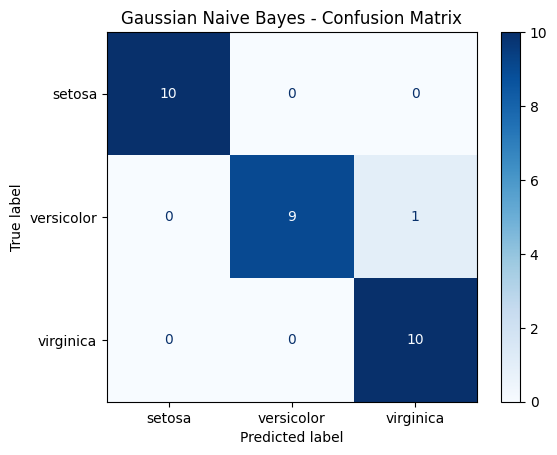

In [79]:
# confusion matrix
cm = confusion_matrix(y_test, y_pred)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

cm_display.plot(cmap="Blues")
plt.title("Gaussian Naive Bayes - Confusion Matrix")
plt.show()

Task 7: Test the model on new input/unseen data.

In [80]:
# new sample 
new_sample = pd.DataFrame([[5.1, 3.5, 1.4, 0.2]], columns=data.feature_names)

In [81]:
# predict the species
prediction = model.predict(new_sample)

In [82]:
# print predicted class
predicted_species = data.target_names[prediction[0]]

print("New sample:", new_sample.values[0])
print("Predicted Iris species:", predicted_species)

New sample: [5.1 3.5 1.4 0.2]
Predicted Iris species: setosa
